In [30]:
from typing import TypedDict, Annotated
import random
from langgraph.graph import StateGraph, START, END, add_messages

In [31]:
class AgentState(TypedDict):
    name: str
    numbers: list[int]
    greeting: str

In [32]:
def take_greetings(state: AgentState) -> AgentState:
    state['greeting'] = f'Hii {state["name"]}'
    return state

def get_random_number(state: AgentState) -> AgentState:
    numbers = state.get('numbers', [])
    numbers.append(random.randint(1, 9))
    state['numbers'] = numbers
    return state

def loop_the_number(state: AgentState):
    if len(state['numbers']) < 5:
        return 'get_random_number'
    return "END"

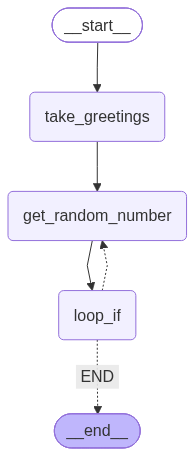

In [35]:
graph = StateGraph(AgentState)

graph.add_node('take_greetings', take_greetings)
graph.add_node('get_random_number', get_random_number)
graph.add_node('loop_if', lambda state: state)


graph.set_entry_point('take_greetings')

graph.add_edge('take_greetings', 'get_random_number')
graph.add_edge('get_random_number', 'loop_if')

graph.add_conditional_edges('loop_if', loop_the_number, {
    'get_random_number': 'get_random_number',
    'END': END
})

workflow = graph.compile()

workflow

In [34]:
workflow.invoke({'name': 'UV', 'numbers': []})

{'name': 'UV', 'numbers': [8, 7, 6, 4, 3], 'greeting': 'Hii UV'}